# Anas Al Hamzi

## Lab 9 - 2240003869

# **Lab 9 - Morphological Operations**

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

imgFile = 'Erosion.jpg'

# **Erosion Operations**

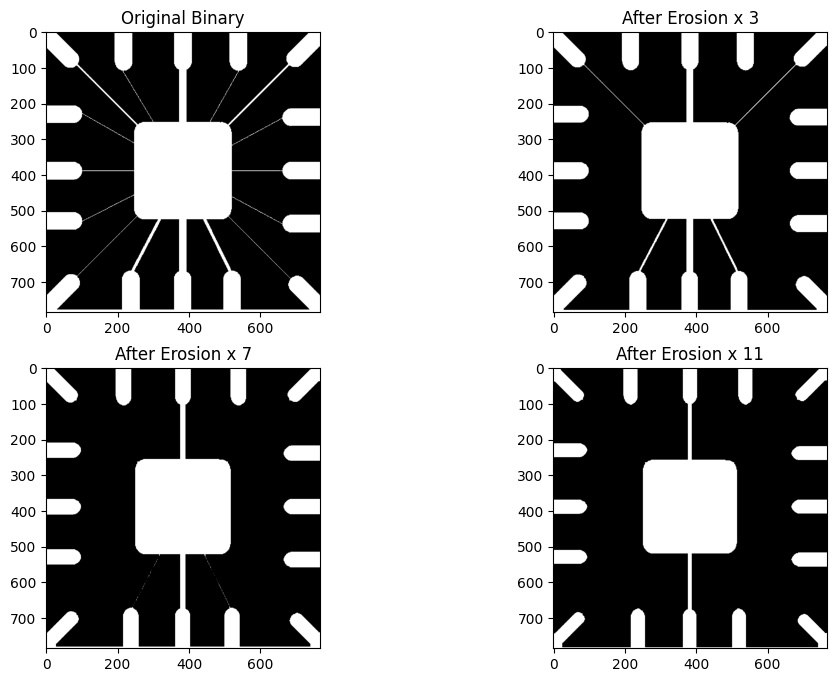

In [2]:

# 1. Load image and convert to grayscale
img = cv2.imread(imgFile, 0)

# 2. Binarize the image (Otsu's method works well for varying light)
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 3. Define a 3x3 kernel (all ones), you can define kernel of size 5x5, 7x7, ... any odd x odd
# Larger kernels lead to more aggressive erosion

kernel3 = np.ones((3, 3), np.uint8)
kernel7 = np.ones((7, 7), np.uint8)
kernel11 = np.ones((11, 11), np.uint8)

# 4. Apply erosion
# 'iterations' determines how many times the operation is repeated,
# ===> You can change iterations values to apply same process multiple times.

eroded_img3 = cv2.erode(binary, kernel3, iterations=1)
eroded_img7 = cv2.erode(binary, kernel7, iterations=1)
eroded_img11 = cv2.erode(binary, kernel11, iterations=1)

# 5. Display comparison
plt.figure(figsize=(12, 8))
plt.subplot(2, 2, 1), plt.imshow(binary, 'gray'), plt.title('Original Binary')
plt.subplot(2, 2, 2), plt.imshow(eroded_img3, 'gray'), plt.title('After Erosion x 3')
plt.subplot(2, 2, 3), plt.imshow(eroded_img7, 'gray'), plt.title('After Erosion x 7')
plt.subplot(2, 2, 4), plt.imshow(eroded_img11, 'gray'), plt.title('After Erosion x 11')


plt.show()


# **Dilation Operations**

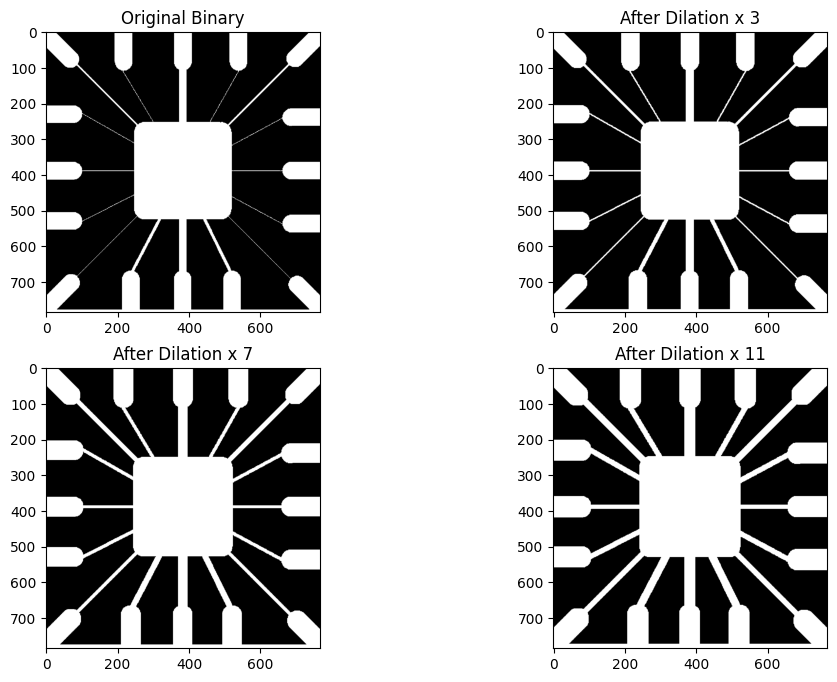

In [3]:

# 1. Load image and convert to grayscale
img = cv2.imread(imgFile, 0)

# 2. Binarize the image (Otsu's method works well for varying light)
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 3. Define a 3x3 kernel (all ones), you can define kernel of size 5x5, 7x7, ... any odd x odd
# Larger kernels lead to more aggressive erosion

kernel3 = np.ones((3, 3), np.uint8)
kernel7 = np.ones((7, 7), np.uint8)
kernel11 = np.ones((11, 11), np.uint8)

# 4. Apply erosion
# 'iterations' determines how many times the operation is repeated,
# ===> You can change iterations values to apply same process multiple times.

eroded_img3 = cv2.dilate(binary, kernel3, iterations=1)
eroded_img7 = cv2.dilate(binary, kernel7, iterations=1)
eroded_img11 = cv2.dilate(binary, kernel11, iterations=1)

# 5. Display comparison
plt.figure(figsize=(12, 8))
plt.subplot(2, 2, 1), plt.imshow(binary, 'gray'), plt.title('Original Binary')
plt.subplot(2, 2, 2), plt.imshow(eroded_img3, 'gray'), plt.title('After Dilation x 3')
plt.subplot(2, 2, 3), plt.imshow(eroded_img7, 'gray'), plt.title('After Dilation x 7')
plt.subplot(2, 2, 4), plt.imshow(eroded_img11, 'gray'), plt.title('After Dilation x 11')


plt.show()


# **Morphological Open Operations**

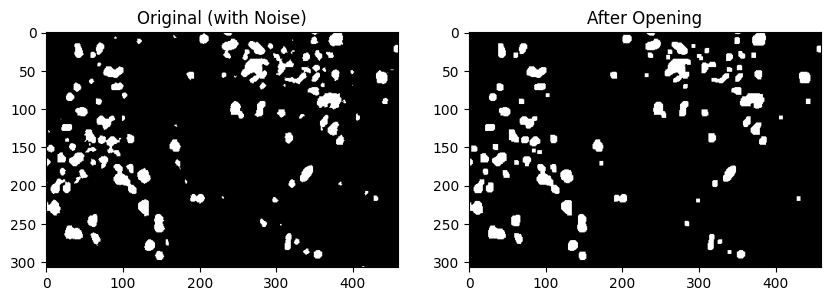

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

imgFile = 'Open_Closing.jpg'

# 1. Load image and binarize
img = cv2.imread(imgFile, 0)
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 2. Define kernel (a 5x5 square is a good starting point)
kernel = np.ones((5, 5), np.uint8)

# 3. Apply Opening
# This is equivalent to: dilate(erode(binary))
opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)

# 4. Display comparison
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1), plt.imshow(binary, 'gray'), plt.title('Original (with Noise)')
plt.subplot(1, 2, 2), plt.imshow(opening, 'gray'), plt.title('After Opening')
plt.show()


# **Closing Morphological Operation**

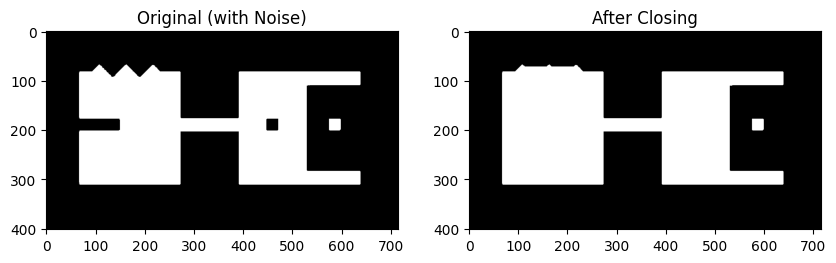

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

imgFile = 'Opening2.jpg'

# 1. Load image and binarize
img = cv2.imread(imgFile, 0)
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 2. Define kernel (a 45x45 square is a good starting point)
kernel = np.ones((45, 45), np.uint8)

# 3. Apply Opening
# Effectively: cv2.erode(cv2.dilate(binary, kernel), kernel)
closing = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

# 4. Display comparison
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1), plt.imshow(binary, 'gray'), plt.title('Original (with Noise)')
plt.subplot(1, 2, 2), plt.imshow(closing, 'gray'), plt.title('After Closing')
plt.show()


# **Boundaries Extractions**

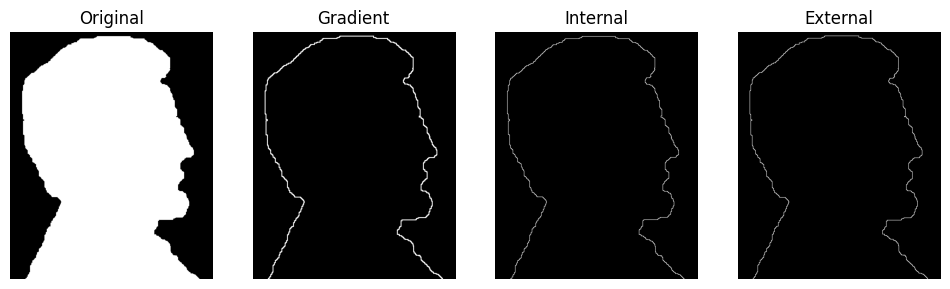

In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


imgFile = 'BoundaryExtraction.jpg'
# 1. Load and binarize the image (foreground must be white)
img = cv2.imread(imgFile, 0)
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 2. Define a kernel (the size controls boundary thickness)
kernel = np.ones((3, 3), np.uint8)

# 3. Method A: Morphological Gradient (Built-in standard)
gradient = cv2.morphologyEx(binary, cv2.MORPH_GRADIENT, kernel)

# 4. Method B: Internal Boundary (Original - Eroded)
eroded = cv2.erode(binary, kernel)
internal = cv2.subtract(binary, eroded)

# 5. Method C: External Boundary (Dilated - Original)
dilated = cv2.dilate(binary, kernel)
external = cv2.subtract(dilated, binary)

# Visualization
titles = ['Original', 'Gradient', 'Internal', 'External']
images = [binary, gradient, internal, external]

plt.figure(figsize=(12, 4))
for i in range(4):
    plt.subplot(1, 4, i+1)
    plt.imshow(images[i], 'gray')
    plt.title(titles[i])
    plt.axis('off')
plt.show()

# **Task 1: Apply Morphological Operations to a New Image**

Selected image: `Balls.png`

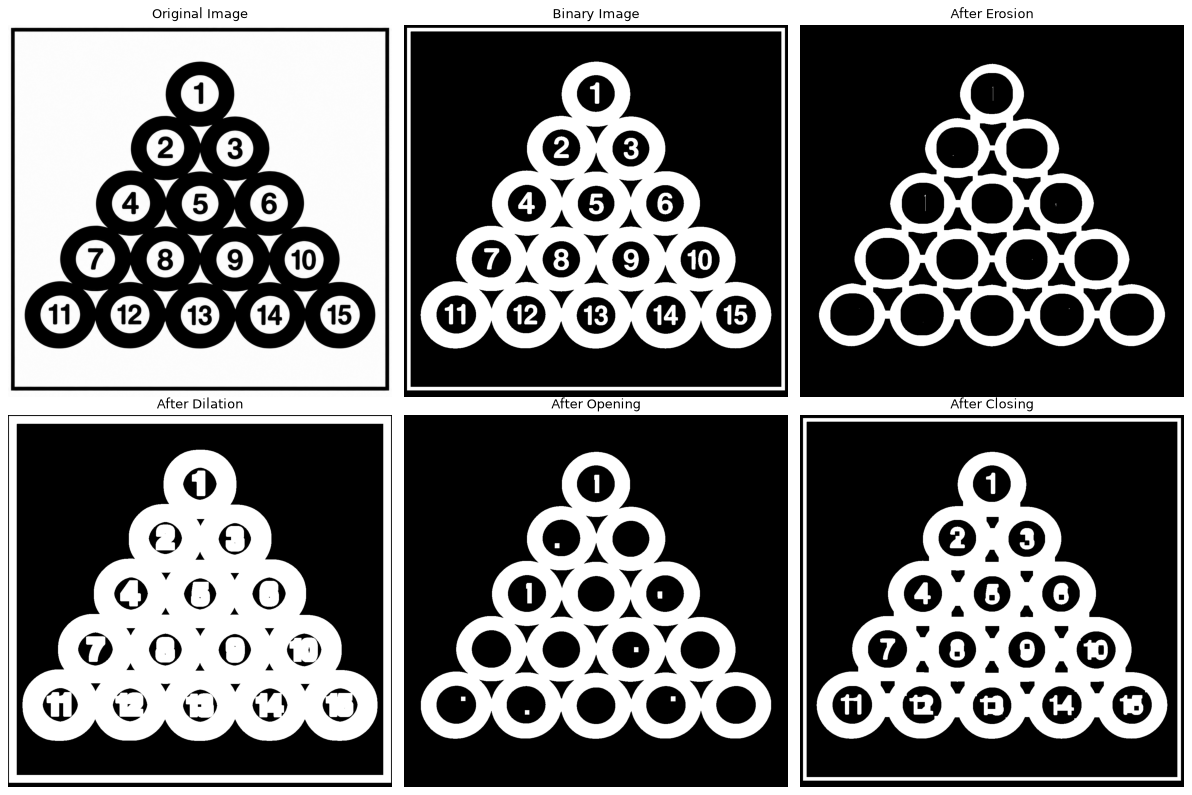

In [ ]:
imgFile = 'Balls.png'

img = cv2.imread(imgFile, 0)
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

kernel = np.ones((15, 15), np.uint8)

eroded = cv2.erode(binary, kernel, iterations=1)
dilated = cv2.dilate(binary, kernel, iterations=1)
opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)
closing = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

plt.figure(figsize=(15, 10))
plt.subplot(2, 3, 1), plt.imshow(img, 'gray'), plt.title('Original Image'), plt.axis('off')
plt.subplot(2, 3, 2), plt.imshow(binary, 'gray'), plt.title('Binary Image'), plt.axis('off')
plt.subplot(2, 3, 3), plt.imshow(eroded, 'gray'), plt.title('After Erosion'), plt.axis('off')
plt.subplot(2, 3, 4), plt.imshow(dilated, 'gray'), plt.title('After Dilation'), plt.axis('off')
plt.subplot(2, 3, 5), plt.imshow(opening, 'gray'), plt.title('After Opening'), plt.axis('off')
plt.subplot(2, 3, 6), plt.imshow(closing, 'gray'), plt.title('After Closing'), plt.axis('off')
plt.tight_layout()
plt.show()

# **Task 2: Experiment with Structuring Elements**

Erosion and dilation with square, cross and ellipse structuring elements of size 3x3, 5x5 and 7x7.

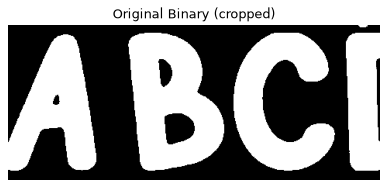

In [ ]:
imgFile = 'Erosion2.jpg'

img = cv2.imread(imgFile, 0)
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
crop = binary[0:200, 0:480]

shapes = {'Square': cv2.MORPH_RECT, 'Cross': cv2.MORPH_CROSS, 'Ellipse': cv2.MORPH_ELLIPSE}
sizes = [3, 5, 7]

plt.figure(figsize=(6, 3))
plt.imshow(crop, 'gray'), plt.title('Original Binary (cropped)'), plt.axis('off')
plt.show()

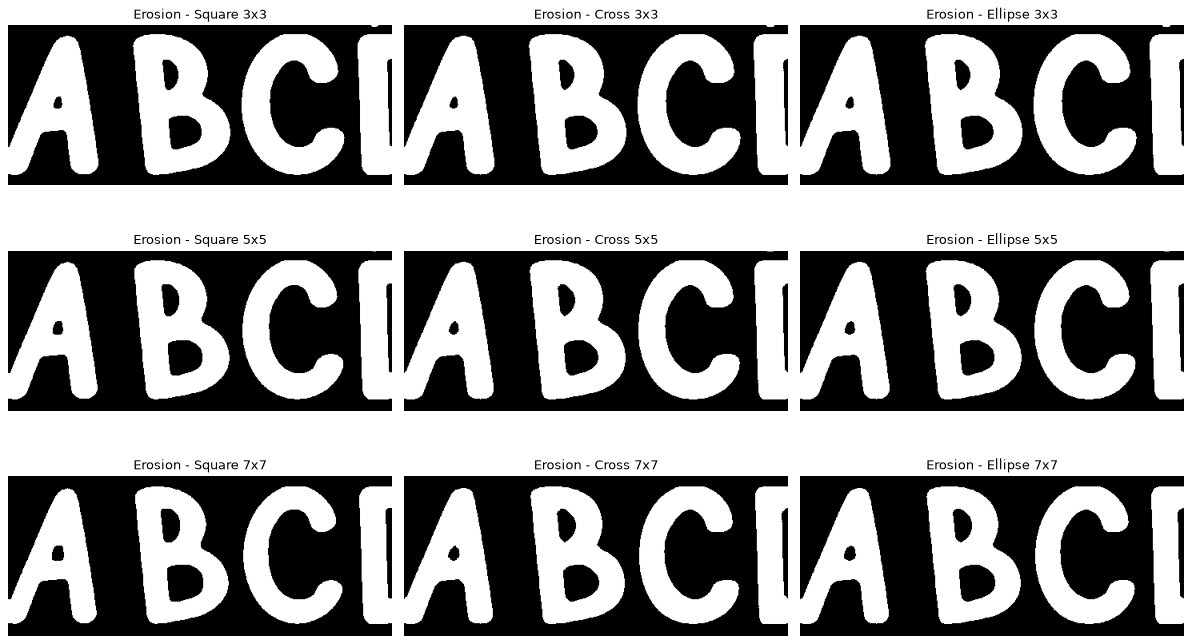

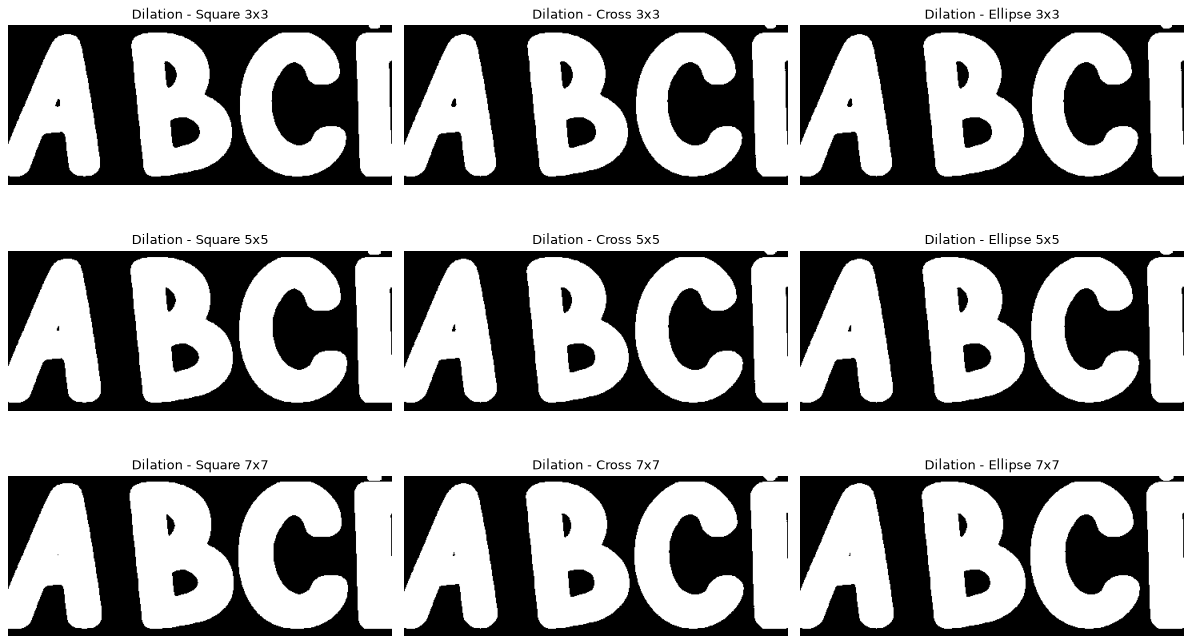

In [ ]:
for op_name, op in [('Erosion', cv2.erode), ('Dilation', cv2.dilate)]:
    plt.figure(figsize=(15, 9))
    for r, size in enumerate(sizes):
        for c, (shape_name, shape) in enumerate(shapes.items()):
            se = cv2.getStructuringElement(shape, (size, size))
            result = op(crop, se)
            plt.subplot(3, 3, r * 3 + c + 1)
            plt.imshow(result, 'gray')
            plt.title(f'{op_name} - {shape_name} {size}x{size}')
            plt.axis('off')
    plt.tight_layout()
    plt.show()

In [ ]:
print(f"{'Shape':10}{'Kernel':8}{'Erosion':>10}{'Dilation':>10}")
print(f"{'Original':10}{'-':8}{np.count_nonzero(crop):>10}{np.count_nonzero(crop):>10}")
for size in sizes:
    for shape_name, shape in shapes.items():
        se = cv2.getStructuringElement(shape, (size, size))
        eroded_count = np.count_nonzero(cv2.erode(crop, se))
        dilated_count = np.count_nonzero(cv2.dilate(crop, se))
        print(f"{shape_name:10}{str(size) + 'x' + str(size):8}{eroded_count:>10}{dilated_count:>10}")

Shape     Kernel     Erosion  Dilation
Original  -            45046     45046
Square    3x3          42165     47927
Cross     3x3          42821     47271
Ellipse   3x3          42821     47271
Square    5x5          39289     50794
Cross     5x5          40611     49481
Ellipse   5x5          40108     49982
Square    7x7          36420     53626
Cross     7x7          38403     51672
Ellipse   7x7          37883     52185


### **Comparison**

- **Kernel size:** The bigger the kernel, the stronger the effect. For every shape, erosion removes more white pixels and dilation adds more as the size goes from 3x3 to 5x5 to 7x7 (for the square: erosion 42165 -> 39289 -> 36420, dilation 47927 -> 50794 -> 53626, compared with 45046 in the original).
- **Kernel shape:** At the same size, the square changes the image the most, then the ellipse, then the cross (at 7x7 the erosion leaves 36420, 37883 and 38403 white pixels, and the dilation gives 53626, 52185 and 51672).
- **Cross and ellipse at 3x3:** They are the same shape at this size, so the results are identical.
- **Look of the result:** The square removes or adds the same amount in all directions, so corners look more blocky. The cross and the ellipse follow the rounded letter edges more closely and change the shape less.